# Electricity Demand Forecasting

## 1. Data Loading and Cleaning

In [51]:
import numpy as np
import pandas as pd
import seaborn as sns

raw = pd.read_csv("../datasets/household_power_consumption.txt", sep=";", na_values=["?"], low_memory=False)

print(f"Columns: {raw.columns.to_list()}")

print(f"\nDataset Shape: {raw.shape}")

print(f"\nNull Values\n{raw.isna().sum()}")

print(f"\nDuplicate Rows: {raw.duplicated().sum()}")

# Merging the date and time and taking it as index
raw["datetime"] = pd.to_datetime(raw["Date"] + " " + raw["Time"],
        format="%d/%m/%Y %H:%M:%S")

raw = raw.drop(columns=["Date", "Time"])
raw = raw.set_index("datetime")

# Filling the missing values with before or after values
complete = raw.interpolate(method="time")

print(f"\nMissing Summary After Cleaning %\n{round(complete.isna().mean() * 100, 2)}")

# X = complete.drop(columns=["Global_active_power"])

# y = complete["Global_intensity"]

# one row per day
daily = complete.resample("D").mean()

X = daily.copy()
X["yesterday"] = daily["Global_intensity"].shift(1)
X["last_week"] = daily["Global_intensity"].shift(7)
X["dayofweek"] = X.index.dayofweek
X["month"] = X.index.month

# the answer: tomorrow's value
X["tomorrow"] = daily["Global_intensity"].shift(-1)
X = X.dropna()

y = X.pop("tomorrow")

Columns: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Dataset Shape: (2075259, 9)

Null Values
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Duplicate Rows: 0

Missing Summary After Cleaning %
Global_active_power      0.0
Global_reactive_power    0.0
Voltage                  0.0
Global_intensity         0.0
Sub_metering_1           0.0
Sub_metering_2           0.0
Sub_metering_3           0.0
dtype: float64


## 2. Exploratory Data Analysis

<Axes: >

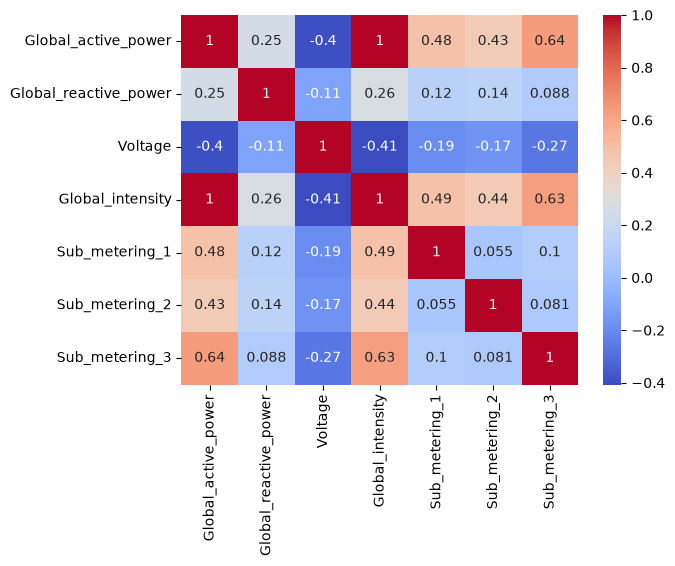

In [52]:
numeric_data = complete.select_dtypes(include="number")

correlation = numeric_data.corr()

sns.heatmap(
    data = correlation,
    annot=True,
    cmap="coolwarm"
)

## 3. Preprocessing and Model Pipeline

In [53]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# split by time: first 80% train, last 20% test
split = int(len(X) * 0.8)
x_train, x_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# baseline: guess tomorrow = today
base_pred = x_test["Global_intensity"]
print("Baseline MAE:", round(mean_absolute_error(y_test, base_pred), 3))
print("Baseline RMSE:", round(np.sqrt(mean_squared_error(y_test, base_pred)), 3))

numeric_cols = list(X.columns)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
])

model = Pipeline([
    ("prep", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
])

model.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Model MAE:", round(mean_absolute_error(y_test, y_pred), 3))
print("Model RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

Baseline MAE: 0.857
Baseline RMSE: 1.201
Model MAE: 0.73
Model RMSE: 0.994


In [54]:
importance = pd.Series(
    model.named_steps["regressor"].feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

Global_active_power      0.401278
month                    0.082947
Sub_metering_2           0.069627
Global_intensity         0.064784
yesterday                0.064268
Global_reactive_power    0.063880
Voltage                  0.061960
last_week                0.054169
Sub_metering_3           0.053437
Sub_metering_1           0.042865
dayofweek                0.040786
dtype: float64


## 4. Global Intensity Actual vs Predicted

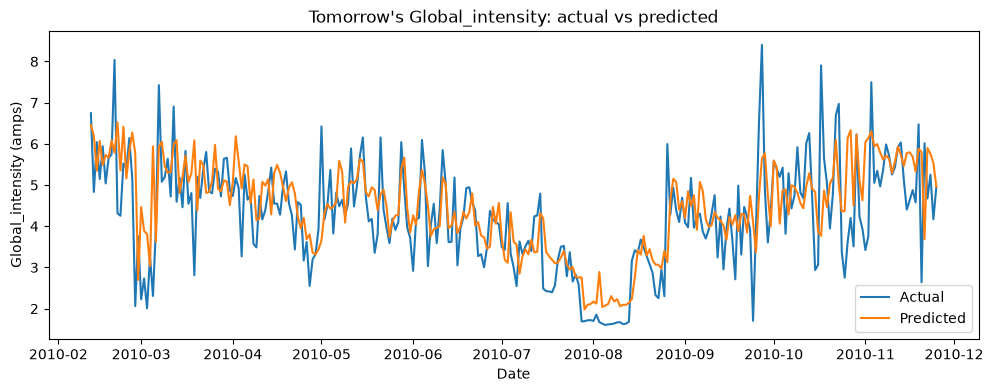

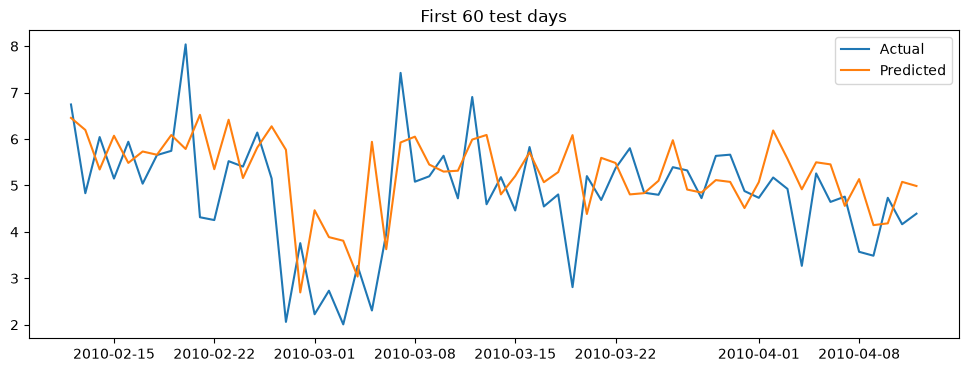

datetime
2010-10-17    4.135318
2010-02-27    3.706651
2010-03-05    3.632753
2010-03-19    3.274530
2010-11-20    3.160095
dtype: float64


In [55]:
import matplotlib.pyplot as plt

# Plot 1: all test days
plt.figure(figsize=(12, 4))
plt.plot(y_test.index, y_test.values, label="Actual")
plt.plot(y_test.index, y_pred, label="Predicted")
plt.title("Tomorrow's Global_intensity: actual vs predicted")
plt.xlabel("Date")
plt.ylabel("Global_intensity (amps)")
plt.legend()
plt.show()

# Plot 2: zoom in on the first 60 test days
days = 60
plt.figure(figsize=(12, 4))
plt.plot(y_test.index[:days], y_test.values[:days], label="Actual")
plt.plot(y_test.index[:days], y_pred[:days], label="Predicted")
plt.title("First 60 test days")
plt.legend()
plt.show()

# The 5 days where the model was most wrong
errors = abs(y_test.values - y_pred)
worst = pd.Series(errors, index=y_test.index).sort_values(ascending=False).head(5)
print(worst)